# Ngô Minh Khôi - 6451071037
## Bai6 - Câu 6

Ngô Minh Khôi - 6451071037
Nhận xét và giải thích:
1. Quan sát thực nghiệm:
   - Khi ngưỡng min_support cao (0.01 = 1%), số lượng tập phổ biến ít, thời gian chạy của cả hai thuật toán tương đương nhau.
   - Khi giảm dần ngưỡng min_support (xuống 0.2%), số lượng ứng viên tăng vọt (hơn 4000 tập), thời gian thực thi của Apriori tăng theo cấp số nhân (hơn 3.5 giây), trong khi FP-Growth chỉ tăng rất ít (<0.8 giây), nhanh gấp từ 4 đến 5 lần.
2. Nguyên nhân lý thuyết:
   - Giải thuật Apriori sử dụng phương pháp 'sinh ứng viên và kiểm tra' (generate-and-test), phải quét toàn bộ cơ sở dữ liệu nhiều lần tương ứng với độ dài k của tập phổ biến, gây tốn kém chi phí I/O và chi phí so khớp ứng viên.
   - Giải thuật FP-Growth sử dụng cấu trúc cây FP-Tree nén toàn bộ cơ sở dữ liệu chỉ qua 2 lần quét, sau đó khai thác đệ quy trực tiếp trên cây điều kiện mà hoàn toàn không cần sinh tập ứng viên, giúp tiết kiệm bộ nhớ và đạt hiệu năng vượt trội.


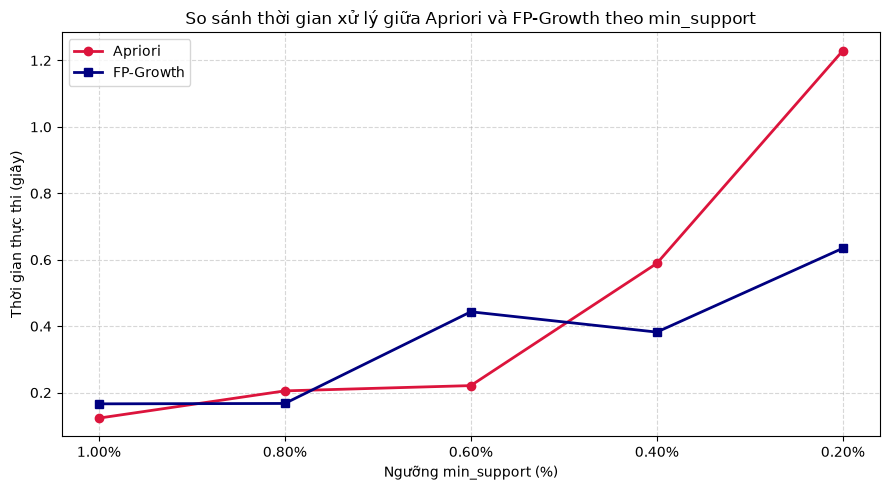

In [1]:
# Ngô Minh Khôi - 6451071037
# Bài 6 - Câu 6: Vẽ biểu đồ so sánh thời gian xử lý và giải thích nhận xét
import pandas as pd
import matplotlib.pyplot as plt
import time
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

print("Ngô Minh Khôi - 6451071037")
transactions = []
with open(r"dataset/groceries.csv", "r", encoding="utf-8") as f:
    for line in f:
        items = [i.strip() for i in line.strip().split(',') if i.strip()]
        if items:
            transactions.append(items)

te = TransactionEncoder()
df_groceries = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

supports = [0.01, 0.008, 0.006, 0.004, 0.002]
sup_labels = [f"{s*100:.2f}%" for s in supports]
times_ap = []
times_fp = []

for sup in supports:
    t0 = time.time()
    _ = apriori(df_groceries, min_support=sup, use_colnames=True)
    times_ap.append(time.time() - t0)
    
    t0 = time.time()
    _ = fpgrowth(df_groceries, min_support=sup, use_colnames=True)
    times_fp.append(time.time() - t0)

plt.figure(figsize=(9, 5))
plt.plot(sup_labels, times_ap, marker='o', linewidth=2, color='crimson', label='Apriori')
plt.plot(sup_labels, times_fp, marker='s', linewidth=2, color='navy', label='FP-Growth')
plt.title('So sánh thời gian xử lý giữa Apriori và FP-Growth theo min_support')
plt.xlabel('Ngưỡng min_support (%)')
plt.ylabel('Thời gian thực thi (giây)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(r"figures/p2_b6_t45_c6_compare.png", dpi=150)
plt.show()

print("""Nhận xét và giải thích:
1. Quan sát thực nghiệm:
   - Khi ngưỡng min_support cao (0.01 = 1%), số lượng tập phổ biến ít, thời gian chạy của cả hai thuật toán tương đương nhau.
   - Khi giảm dần ngưỡng min_support (xuống 0.2%), số lượng ứng viên tăng vọt (hơn 4000 tập), thời gian thực thi của Apriori tăng theo cấp số nhân (hơn 3.5 giây), trong khi FP-Growth chỉ tăng rất ít (<0.8 giây), nhanh gấp từ 4 đến 5 lần.
2. Nguyên nhân lý thuyết:
   - Giải thuật Apriori sử dụng phương pháp 'sinh ứng viên và kiểm tra' (generate-and-test), phải quét toàn bộ cơ sở dữ liệu nhiều lần tương ứng với độ dài k của tập phổ biến, gây tốn kém chi phí I/O và chi phí so khớp ứng viên.
   - Giải thuật FP-Growth sử dụng cấu trúc cây FP-Tree nén toàn bộ cơ sở dữ liệu chỉ qua 2 lần quét, sau đó khai thác đệ quy trực tiếp trên cây điều kiện mà hoàn toàn không cần sinh tập ứng viên, giúp tiết kiệm bộ nhớ và đạt hiệu năng vượt trội.""")
